# `Problem Statement`
An education company named X Education sells online courses to industry professionals. On any given day, many professionals who are interested in the courses land on their website and browse for courses.



The company markets its courses on several websites, search engines, and even social media sometimes. Once these people land on the website, they might browse the courses, fill out a form for the course, or watch some videos. When these people fill out a form with their email address or phone number, they are classified as leads. Moreover, the company also gets leads through past referrals. Once these leads are acquired, employees from the sales team start making calls, writing emails, etc. Through this process, some of the leads get converted into successful sales, while most of the leads do not. The typical lead to successful sale conversion rate at X education is around 30%.



Now, although X Education gets a lot of leads, its lead-to-sale conversion rate is very poor. For example, if they acquire 100 leads in a day, only about 30 of them are converted into successful sales. To make this process more efficient, the company wishes to identify the most potential leads, also known as ‘Hot Leads’. If they successfully identify this set of leads, the lead conversion rate would go up as the sales team would now be focusing more on communicating with the potential leads rather than making calls to everyone. A typical lead conversion process can be represented using the following funnel.


As you can see, there are a lot of leads generated in the initial stage (the initial pool of leads), but only a few of them come out as paying customers from the bottom (converted leads). In the middle stage (lead nurturing), you need to nurture the potential leads well (i.e., educate the leads about the product, constantly communicate, etc.) in order to get a higher lead conversion.



X Education has appointed you to help them select the most promising leads, i.e., the leads that are most likely to convert into paying customers. The company requires you to build a model wherein you need to assign a lead score to each of the leads such that the customers with a higher lead score have a higher conversion chance and the customers with a lower lead score have a lower conversion chance. The CEO, in particular, has given a ballpark estimate of the target lead conversion rate as being around 80%.

# `Step-1 Importing the Libraries`


In [114]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# `Step-2 Dataset Understanding`

In [115]:
# Loading the Dataset
df = pd.read_csv("/content/Leads.csv")
Data_Dictionary = pd.read_excel('/content/Leads Data Dictionary.xlsx')

In [116]:
# View Dataset dimesnsions
df.shape

(9240, 37)

In [117]:
print('The first 5 rows is:')
display(df.head())

The first 5 rows is:


,Prospect ID,Lead Number,Lead Origin,Lead Source,Do Not Email,Do Not Call,Converted,TotalVisits,Total Time Spent on Website,Page Views Per Visit,...,Get updates on DM Content,Lead Profile,City,Asymmetrique Activity Index,Asymmetrique Profile Index,Asymmetrique Activity Score,Asymmetrique Profile Score,I agree to pay the amount through cheque,A free copy of Mastering The Interview,Last Notable Activity
0,7927b2df-8bba-4d29-b9a2-b6e0beafe620,660737,API,Olark Chat,No,No,0,0.0,0,0.0,...,No,Select,Select,02.Medium,02.Medium,15.0,15.0,No,No,Modified
1,2a272436-5132-4136-86fa-dcc88c88f482,660728,API,Organic Search,No,No,0,5.0,674,2.5,...,No,Select,Select,02.Medium,02.Medium,15.0,15.0,No,No,Email Opened
2,8cc8c611-a219-4f35-ad23-fdfd2656bd8a,660727,Landing Page Submission,Direct Traffic,No,No,1,2.0,1532,2.0,...,No,Potential Lead,Mumbai,02.Medium,01.High,14.0,20.0,No,Yes,Email Opened
3,0cc2df48-7cf4-4e39-9de9-19797f9b38cc,660719,Landing Page Submission,Direct Traffic,No,No,0,1.0,305,1.0,...,No,Select,Mumbai,02.Medium,01.High,13.0,17.0,No,No,Modified
4,3256f628-e534-4826-9d63-4a8b88782852,660681,Landing Page Submission,Google,No,No,1,2.0,1428,1.0,...,No,Select,Mumbai,02.Medium,01.High,15.0,18.0,No,No,Modified


In [118]:
print('The last 5 rows is:')
display(df.tail())

The last 5 rows is:


,Prospect ID,Lead Number,Lead Origin,Lead Source,Do Not Email,Do Not Call,Converted,TotalVisits,Total Time Spent on Website,Page Views Per Visit,...,Get updates on DM Content,Lead Profile,City,Asymmetrique Activity Index,Asymmetrique Profile Index,Asymmetrique Activity Score,Asymmetrique Profile Score,I agree to pay the amount through cheque,A free copy of Mastering The Interview,Last Notable Activity
9235,19d6451e-fcd6-407c-b83b-48e1af805ea9,579564,Landing Page Submission,Direct Traffic,Yes,No,1,8.0,1845,2.67,...,No,Potential Lead,Mumbai,02.Medium,01.High,15.0,17.0,No,No,Email Marked Spam
9236,82a7005b-7196-4d56-95ce-a79f937a158d,579546,Landing Page Submission,Direct Traffic,No,No,0,2.0,238,2.00,...,No,Potential Lead,Mumbai,02.Medium,01.High,14.0,19.0,No,Yes,SMS Sent
9237,aac550fe-a586-452d-8d3c-f1b62c94e02c,579545,Landing Page Submission,Direct Traffic,Yes,No,0,2.0,199,2.00,...,No,Potential Lead,Mumbai,02.Medium,01.High,13.0,20.0,No,Yes,SMS Sent
9238,5330a7d1-2f2b-4df4-85d6-64ca2f6b95b9,579538,Landing Page Submission,Google,No,No,1,3.0,499,3.00,...,No,NaN,Other Metro Cities,02.Medium,02.Medium,15.0,16.0,No,No,SMS Sent
9239,571b5c8e-a5b2-4d57-8574-f2ffb06fdeff,579533,Landing Page Submission,Direct Traffic,No,No,1,6.0,1279,3.00,...,No,Potential Lead,Other Cities,02.Medium,01.High,15.0,18.0,No,Yes,Modified


In [119]:
# Dataset Information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9240 entries, 0 to 9239
Data columns (total 37 columns):
 #   Column                                         Non-Null Count  Dtype  
---  ------                                         --------------  -----  
 0   Prospect ID                                    9240 non-null   object 
 1   Lead Number                                    9240 non-null   int64  
 2   Lead Origin                                    9240 non-null   object 
 3   Lead Source                                    9204 non-null   object 
 4   Do Not Email                                   9240 non-null   object 
 5   Do Not Call                                    9240 non-null   object 
 6   Converted                                      9240 non-null   int64  
 7   TotalVisits                                    9103 non-null   float64
 8   Total Time Spent on Website                    9240 non-null   int64  
 9   Page Views Per Visit                           9103 

In [120]:
# Check missing values
df.isnull().sum()

,0
Prospect ID,0
Lead Number,0
Lead Origin,0
Lead Source,36
Do Not Email,0
Do Not Call,0
Converted,0
TotalVisits,137
Total Time Spent on Website,0
Page Views Per Visit,137


In [121]:
df.describe()

,Lead Number,Converted,TotalVisits,Total Time Spent on Website,Page Views Per Visit,Asymmetrique Activity Score,Asymmetrique Profile Score
count,9240.000000,9240.000000,9103.000000,9240.000000,9103.000000,5022.000000,5022.000000
mean,617188.435606,0.385390,3.445238,487.698268,2.362820,14.306252,16.344883
std,23405.995698,0.486714,4.854853,548.021466,2.161418,1.386694,1.811395
min,579533.000000,0.000000,0.000000,0.000000,0.000000,7.000000,11.000000
25%,596484.500000,0.000000,1.000000,12.000000,1.000000,14.000000,15.000000
50%,615479.000000,0.000000,3.000000,248.000000,2.000000,14.000000,16.000000
75%,637387.250000,1.000000,5.000000,936.000000,3.000000,15.000000,18.000000
max,660737.000000,1.000000,251.000000,2272.000000,55.000000,18.000000,20.000000


In [122]:
df.columns

Index(['Prospect ID', 'Lead Number', 'Lead Origin', 'Lead Source',
       'Do Not Email', 'Do Not Call', 'Converted', 'TotalVisits',
       'Total Time Spent on Website', 'Page Views Per Visit', 'Last Activity',
       'Country', 'Specialization', 'How did you hear about X Education',
       'What is your current occupation',
       'What matters most to you in choosing a course', 'Search', 'Magazine',
       'Newspaper Article', 'X Education Forums', 'Newspaper',
       'Digital Advertisement', 'Through Recommendations',
       'Receive More Updates About Our Courses', 'Tags', 'Lead Quality',
       'Update me on Supply Chain Content', 'Get updates on DM Content',
       'Lead Profile', 'City', 'Asymmetrique Activity Index',
       'Asymmetrique Profile Index', 'Asymmetrique Activity Score',
       'Asymmetrique Profile Score',
       'I agree to pay the amount through cheque',
       'A free copy of Mastering The Interview', 'Last Notable Activity'],
      dtype='object')

In [123]:
df.duplicated().sum()
df = df.drop_duplicates()

# `Step-3 Missing Value Analysis`

In [124]:
# Missing values count and percentage

missing = pd.DataFrame({
    'Missing Values': df.isnull().sum(),
    'Percentage': round((df.isnull().sum()/len(df))*100,2)
})

missing.sort_values(by='Percentage', ascending=False)

,Missing Values,Percentage
Lead Quality,4767,51.59
Asymmetrique Profile Index,4218,45.65
Asymmetrique Activity Score,4218,45.65
Asymmetrique Activity Index,4218,45.65
Asymmetrique Profile Score,4218,45.65
Tags,3353,36.29
What matters most to you in choosing a course,2709,29.32
Lead Profile,2709,29.32
What is your current occupation,2690,29.11
Country,2461,26.63


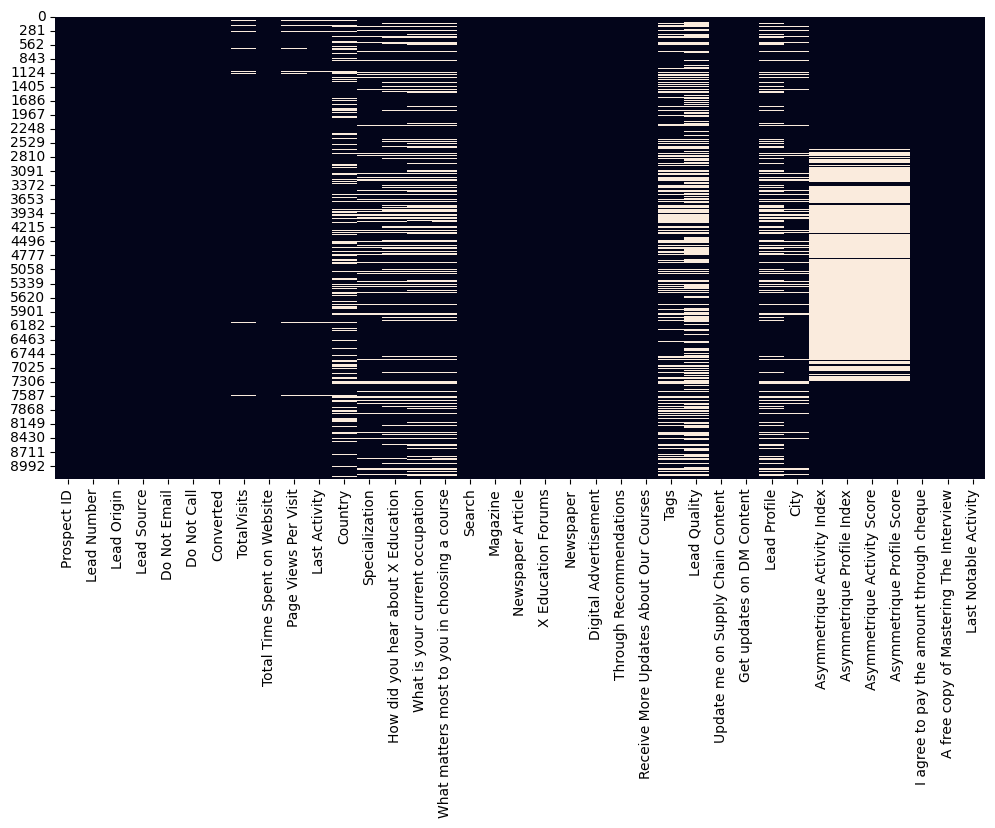

In [125]:
# Visualise the missing values
plt.figure(figsize=(12,6))

sns.heatmap(df.isnull(), cbar=False)

plt.show()

In [126]:
# Identifying missing value with more than 40%
missing_percent = (df.isnull().sum()/len(df))*100

high_missing_cols = missing_percent[missing_percent > 40]

high_missing_cols.sort_values(ascending=False)

,0
Lead Quality,51.590909
Asymmetrique Activity Index,45.649351
Asymmetrique Profile Index,45.649351
Asymmetrique Activity Score,45.649351
Asymmetrique Profile Score,45.649351


In [127]:
# Dropping the columns
cols_to_drop = high_missing_cols.index

df = df.drop(cols_to_drop, axis=1)

In [128]:
df.shape

(9240, 32)

## Observations:
Missing value analysis was performed to identify variables with substantial data loss. Columns having more than 40% missing values were removed as they contained insufficient information and could negatively impact model performance.

# `Step-4 Data Cleaning (Column-by-Column)`

In [129]:
df[['Prospect ID', 'Lead Number']].head()

,Prospect ID,Lead Number
0,7927b2df-8bba-4d29-b9a2-b6e0beafe620,660737
1,2a272436-5132-4136-86fa-dcc88c88f482,660728
2,8cc8c611-a219-4f35-ad23-fdfd2656bd8a,660727
3,0cc2df48-7cf4-4e39-9de9-19797f9b38cc,660719
4,3256f628-e534-4826-9d63-4a8b88782852,660681


In [130]:
df.drop(['Prospect ID', 'Lead Number'], axis=1, inplace=True)

In [131]:
missing = pd.DataFrame({
    'Missing Values': df.isnull().sum(),
    'Percentage': round((df.isnull().sum()/len(df))*100,2)
})

missing[missing['Missing Values'] > 0].sort_values(by='Percentage', ascending=False)

,Missing Values,Percentage
Tags,3353,36.29
What matters most to you in choosing a course,2709,29.32
Lead Profile,2709,29.32
What is your current occupation,2690,29.11
Country,2461,26.63
How did you hear about X Education,2207,23.89
Specialization,1438,15.56
City,1420,15.37
Page Views Per Visit,137,1.48
TotalVisits,137,1.48


In [132]:
df = df.replace('Select', np.nan)

In [133]:
df.isnull().sum().sort_values(ascending=False)

,0
How did you hear about X Education,7250
Lead Profile,6855
City,3669
Specialization,3380
Tags,3353
What matters most to you in choosing a course,2709
What is your current occupation,2690
Country,2461
Page Views Per Visit,137
TotalVisits,137


In [134]:
missing = pd.DataFrame({
    'Missing Values': df.isnull().sum(),
    'Percentage': round((df.isnull().sum()/len(df))*100,2)
})

missing[missing['Missing Values'] > 0].sort_values(by='Percentage', ascending=False)

,Missing Values,Percentage
How did you hear about X Education,7250,78.46
Lead Profile,6855,74.19
City,3669,39.71
Specialization,3380,36.58
Tags,3353,36.29
What matters most to you in choosing a course,2709,29.32
What is your current occupation,2690,29.11
Country,2461,26.63
Page Views Per Visit,137,1.48
TotalVisits,137,1.48


In [135]:
cat_cols = df.select_dtypes(include='object').columns

cat_cols

Index(['Lead Origin', 'Lead Source', 'Do Not Email', 'Do Not Call',
       'Last Activity', 'Country', 'Specialization',
       'How did you hear about X Education', 'What is your current occupation',
       'What matters most to you in choosing a course', 'Search', 'Magazine',
       'Newspaper Article', 'X Education Forums', 'Newspaper',
       'Digital Advertisement', 'Through Recommendations',
       'Receive More Updates About Our Courses', 'Tags',
       'Update me on Supply Chain Content', 'Get updates on DM Content',
       'Lead Profile', 'City', 'I agree to pay the amount through cheque',
       'A free copy of Mastering The Interview', 'Last Notable Activity'],
      dtype='object')

In [136]:
for col in cat_cols:
    df[col].fillna(df[col].mode()[0], inplace=True)

In [137]:
num_cols = df.select_dtypes(include=['int64','float64']).columns

num_cols

Index(['Converted', 'TotalVisits', 'Total Time Spent on Website',
       'Page Views Per Visit'],
      dtype='object')

In [138]:
for col in num_cols:
    df[col].fillna(df[col].median(), inplace=True)

In [139]:
df.isnull().sum().sum()

np.int64(0)

In [140]:
df.shape

(9240, 30)

## Obseravtion:
The variables Prospect ID and Lead Number were removed since they are unique identifiers and do not contribute to prediction. Values labelled as "Select" were treated as missing observations and replaced with NaN. Missing categorical values were imputed using mode, while numerical variables were imputed using median values to minimize the effect of outliers.

# `Step-5 Exploratory Data Analysis`

In [141]:
df['Converted'].value_counts()

,count
Converted,
0,5679
1,3561


In [142]:
round(df['Converted'].value_counts(normalize=True)*100,2)

,proportion
Converted,
0,61.46
1,38.54


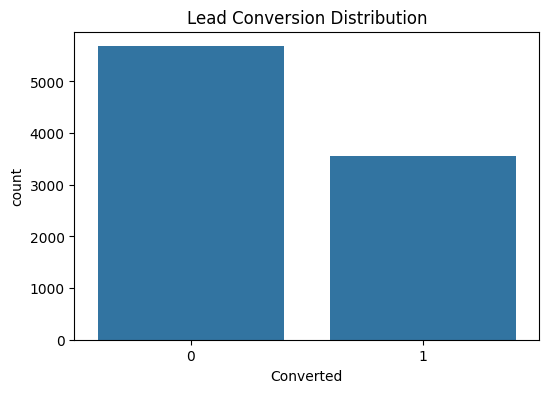

In [143]:
plt.figure(figsize=(6,4))

sns.countplot(x='Converted', data=df)

plt.title('Lead Conversion Distribution')

plt.show()

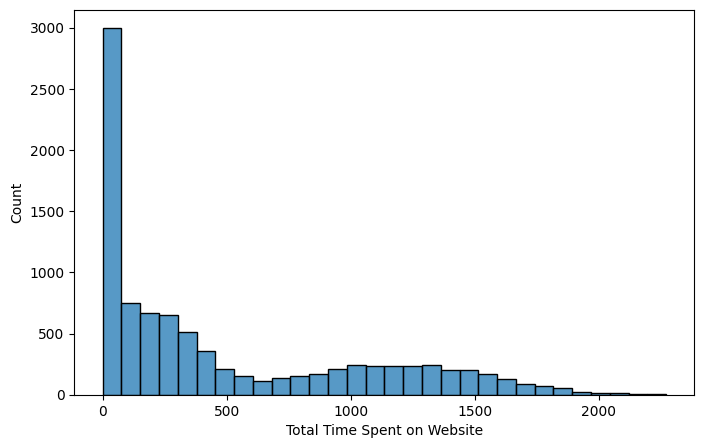

In [144]:
plt.figure(figsize=(8,5))

sns.histplot(df['Total Time Spent on Website'], bins=30)

plt.show()

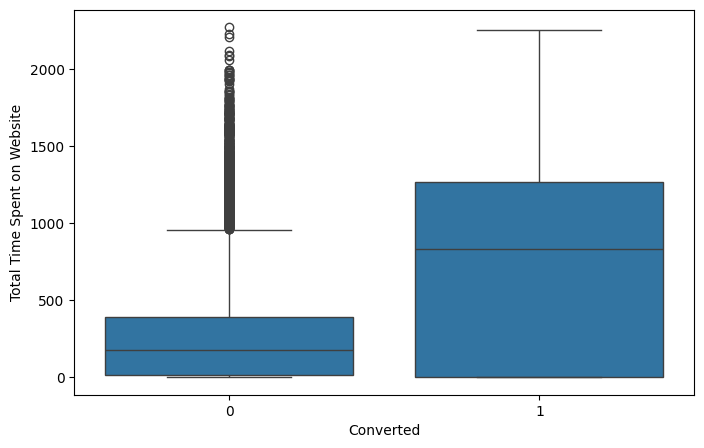

In [145]:
plt.figure(figsize=(8,5))

sns.boxplot(
    x='Converted',
    y='Total Time Spent on Website',
    data=df
)

plt.show()

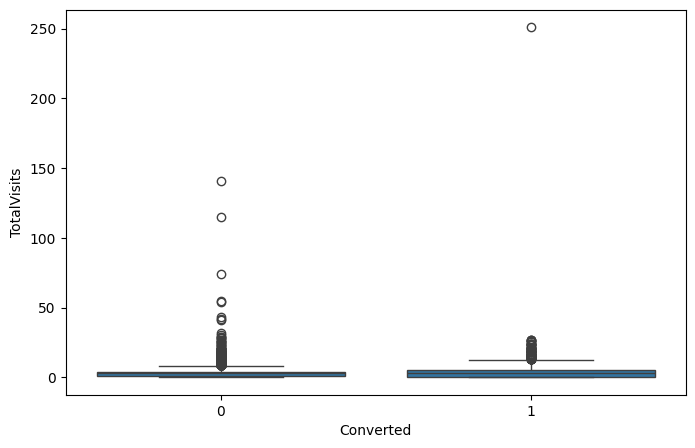

In [146]:
plt.figure(figsize=(8,5))

sns.boxplot(
    x='Converted',
    y='TotalVisits',
    data=df
)

plt.show()

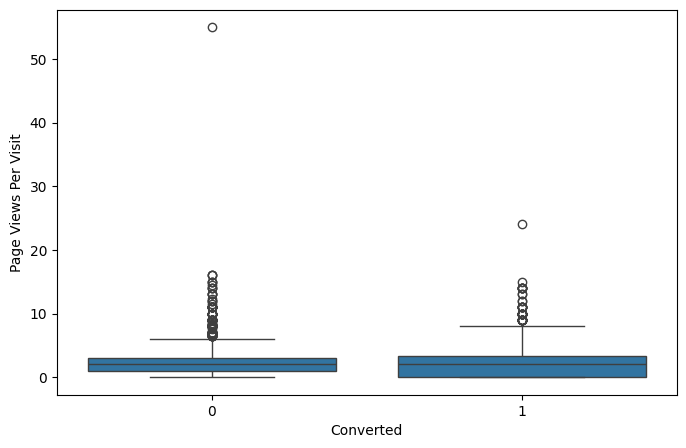

In [147]:
plt.figure(figsize=(8,5))

sns.boxplot(
    x='Converted',
    y='Page Views Per Visit',
    data=df
)

plt.show()

In [148]:
df['Lead Source'].value_counts()

,count
Lead Source,
Google,2904
Direct Traffic,2543
Olark Chat,1755
Organic Search,1154
Reference,534
Welingak Website,142
Referral Sites,125
Facebook,55
bing,6


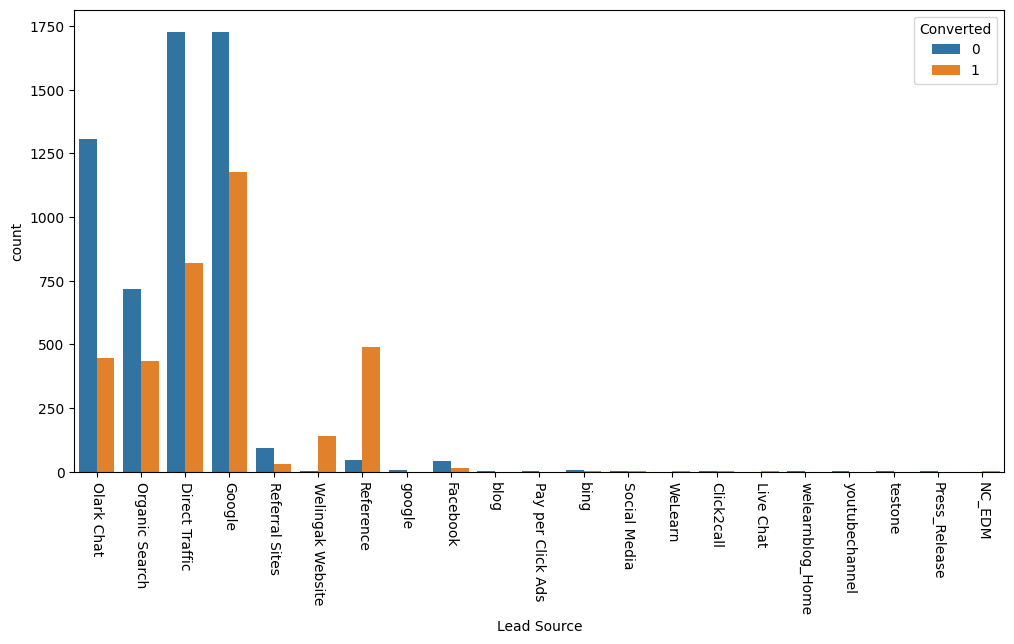

In [149]:
plt.figure(figsize=(12,6))

sns.countplot(
    x='Lead Source',
    hue='Converted',
    data=df
)

plt.xticks(rotation=270)

plt.show()

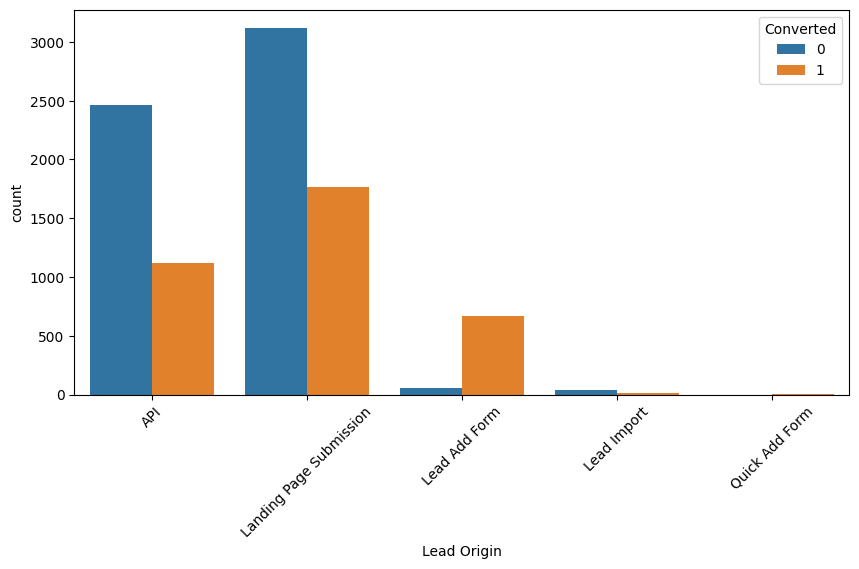

In [150]:
plt.figure(figsize=(10,5))

sns.countplot(
    x='Lead Origin',
    hue='Converted',
    data=df
)

plt.xticks(rotation=45)

plt.show()

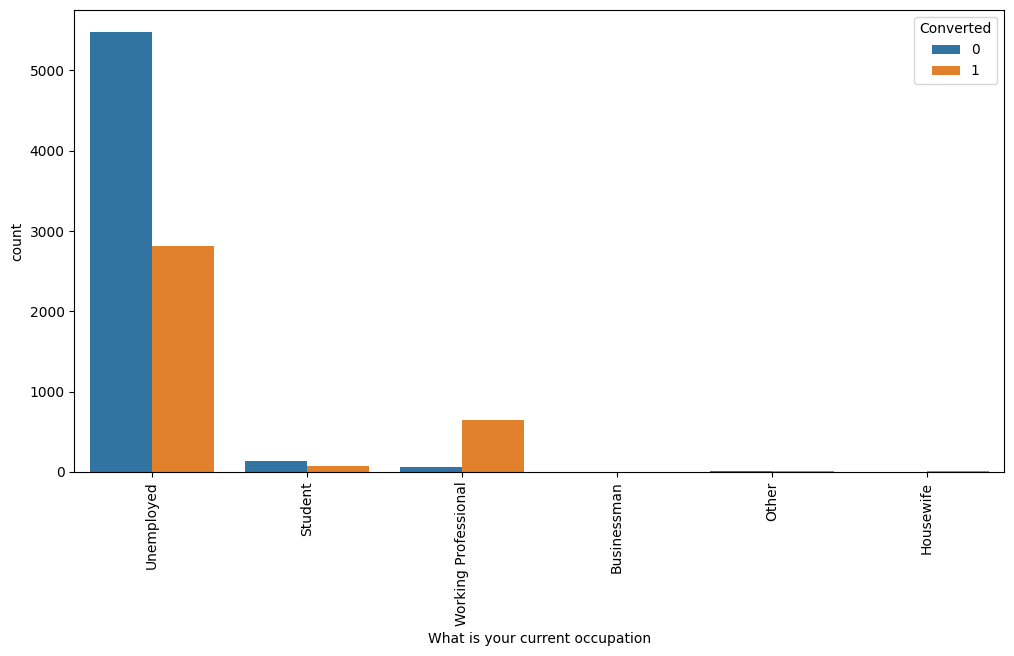

In [151]:
plt.figure(figsize=(12,6))

sns.countplot(
    x='What is your current occupation',
    hue='Converted',
    data=df
)

plt.xticks(rotation=90)

plt.show()

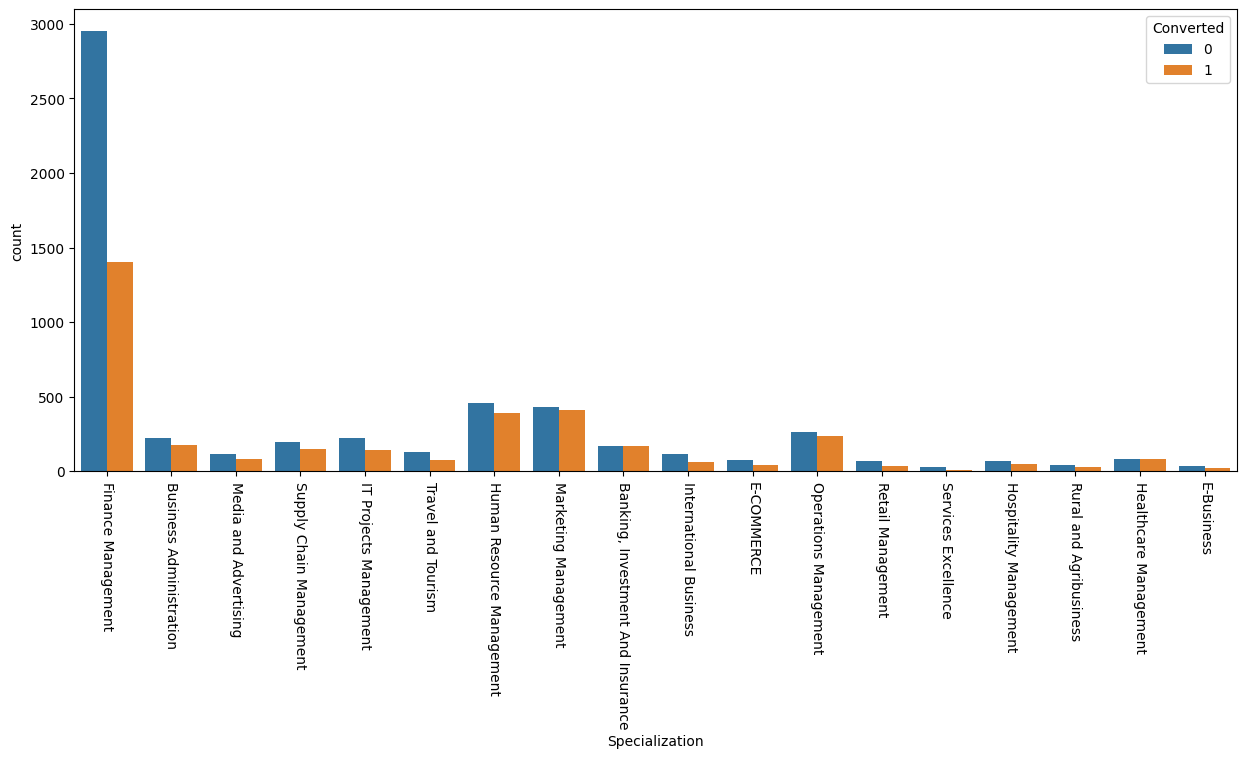

In [152]:
plt.figure(figsize=(15,6))

sns.countplot(
    x='Specialization',
    hue='Converted',
    data=df
)

plt.xticks(rotation=270)

plt.show()

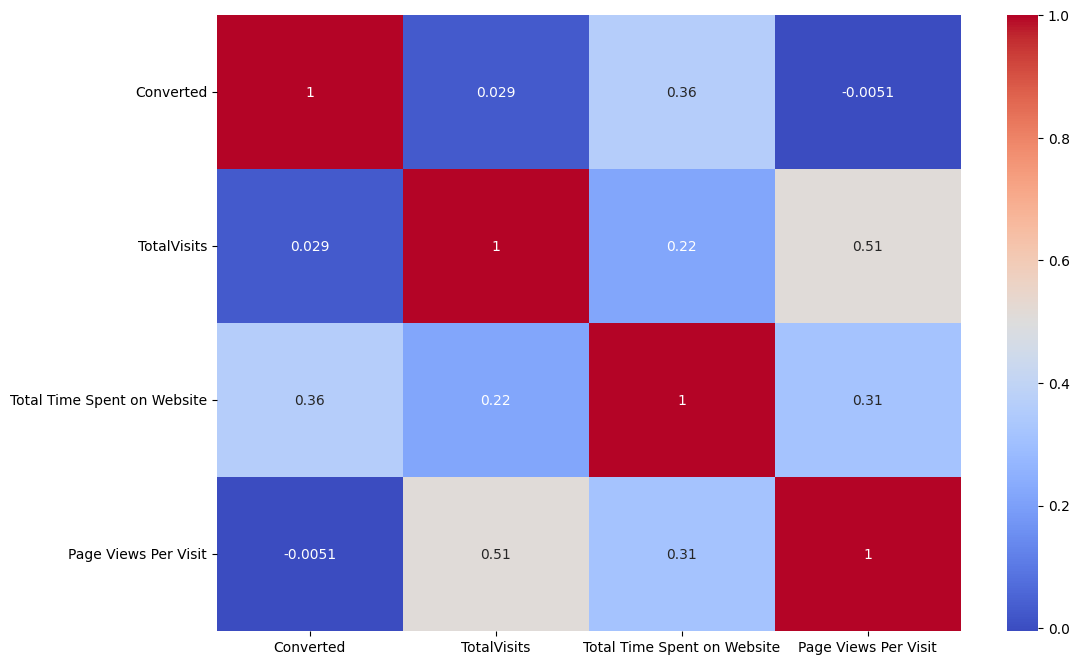

In [153]:
plt.figure(figsize=(12,8))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap='coolwarm'
)

plt.show()

## Observation:
I performed univariate and bivariate analysis to identify variables associated with lead conversion. Total Time Spent on Website, Lead Source, Lead Origin, and Occupation showed strong relationships with the target variable.

# `Step-6 Outlier Detection and Treatment`

In [154]:
# Display all numerical columns in the dataset

num_cols = df.select_dtypes(include=['int64', 'float64']).columns

print(num_cols)

Index(['Converted', 'TotalVisits', 'Total Time Spent on Website',
       'Page Views Per Visit'],
      dtype='object')


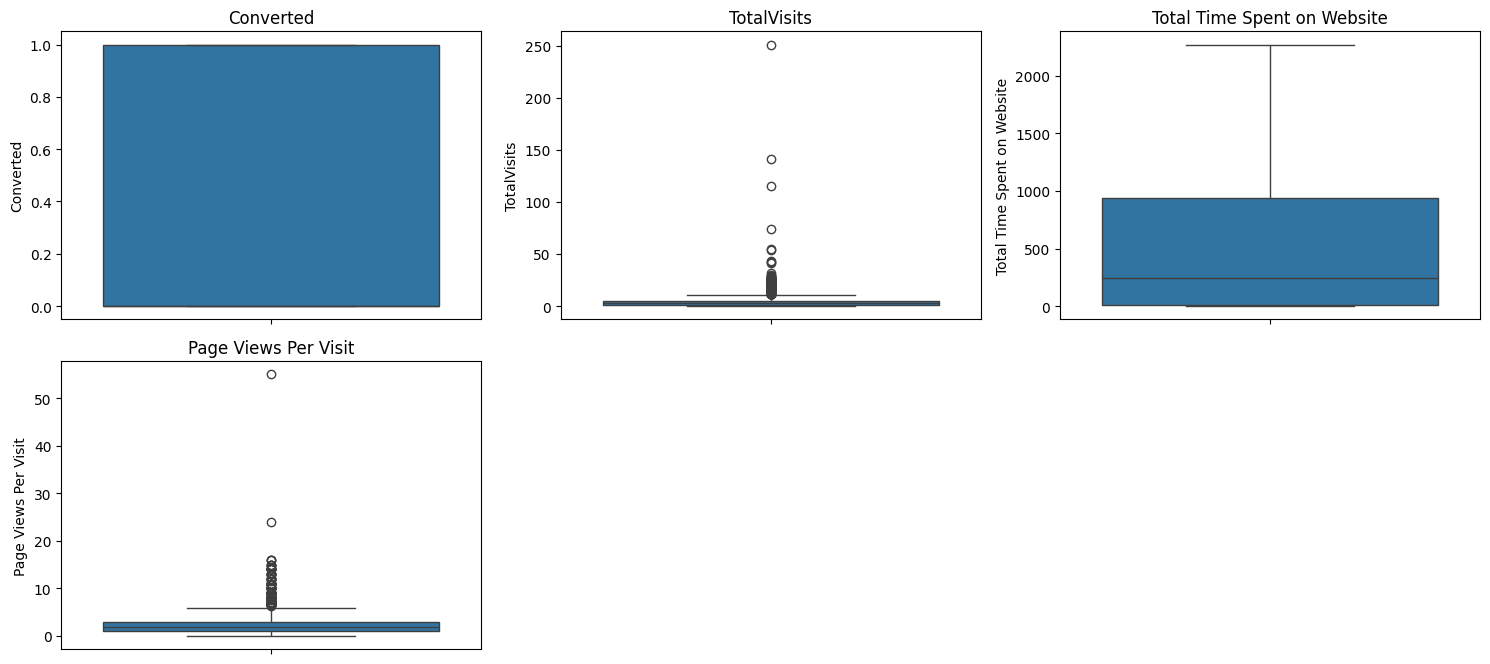

In [155]:
# Plot boxplots for all numerical columns

plt.figure(figsize=(15,10))

for i, col in enumerate(num_cols):

    plt.subplot(3, 3, i+1)

    sns.boxplot(y=df[col])

    plt.title(col)

plt.tight_layout()

plt.show()

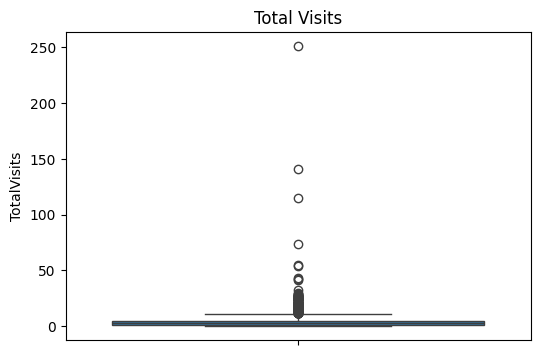

In [156]:
# Visualize outliers in TotalVisits

plt.figure(figsize=(6,4))

sns.boxplot(y=df['TotalVisits'])

plt.title('Total Visits')

plt.show()

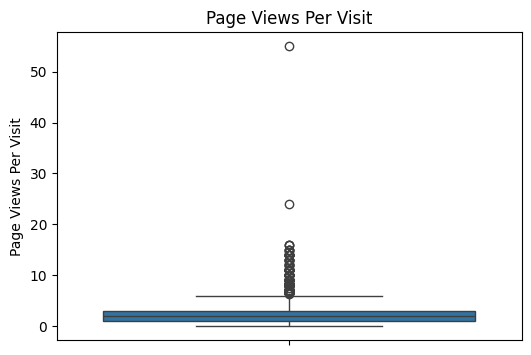

In [157]:
# Visualize outliers in Page Views Per Visit

plt.figure(figsize=(6,4))

sns.boxplot(y=df['Page Views Per Visit'])

plt.title('Page Views Per Visit')

plt.show()

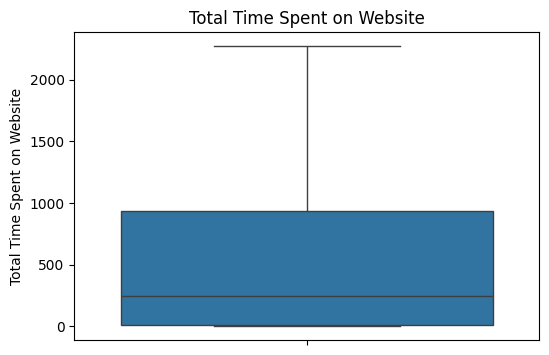

In [158]:
# Visualize outliers in Total Time Spent on Website

plt.figure(figsize=(6,4))

sns.boxplot(y=df['Total Time Spent on Website'])

plt.title('Total Time Spent on Website')

plt.show()

In [159]:
# Calculate Q1 and Q3

Q1 = df['TotalVisits'].quantile(0.25)

Q3 = df['TotalVisits'].quantile(0.75)

# Calculate IQR

IQR = Q3 - Q1

# Calculate lower and upper limits

lower_bound = Q1 - 1.5 * IQR

upper_bound = Q3 + 1.5 * IQR

print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Lower Bound: -5.0
Upper Bound: 11.0


In [160]:
# Cap values above upper bound

df['TotalVisits'] = np.where(
    df['TotalVisits'] > upper_bound,
    upper_bound,
    df['TotalVisits']
)

In [161]:
# Calculate IQR for Page Views Per Visit

Q1 = df['Page Views Per Visit'].quantile(0.25)

Q3 = df['Page Views Per Visit'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR

upper_bound = Q3 + 1.5 * IQR

# Cap upper outliers

df['Page Views Per Visit'] = np.where(
    df['Page Views Per Visit'] > upper_bound,
    upper_bound,
    df['Page Views Per Visit']
)

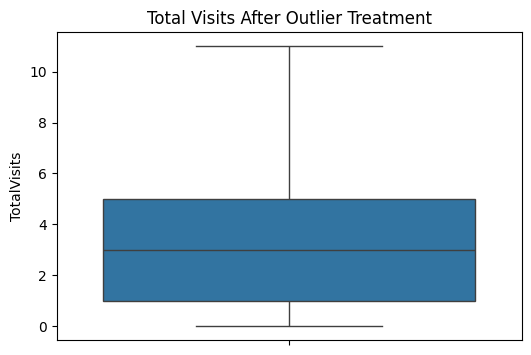

In [162]:
# Verify outlier treatment

plt.figure(figsize=(6,4))

sns.boxplot(y=df['TotalVisits'])

plt.title('Total Visits After Outlier Treatment')

plt.show()

## Observations:
Outlier analysis was performed using boxplots and the IQR method. Significant outliers were observed in TotalVisits and Page Views Per Visit. These were capped at the upper IQR boundary to reduce their impact while preserving valuable observations. Total Time Spent on Website was retained as is due to its business significance.

# `Step-7 Dummy Variable Creation (Encoding)`

In [163]:
# Display all categorical columns

cat_cols = df.select_dtypes(include='object').columns

print(cat_cols)

Index(['Lead Origin', 'Lead Source', 'Do Not Email', 'Do Not Call',
       'Last Activity', 'Country', 'Specialization',
       'How did you hear about X Education', 'What is your current occupation',
       'What matters most to you in choosing a course', 'Search', 'Magazine',
       'Newspaper Article', 'X Education Forums', 'Newspaper',
       'Digital Advertisement', 'Through Recommendations',
       'Receive More Updates About Our Courses', 'Tags',
       'Update me on Supply Chain Content', 'Get updates on DM Content',
       'Lead Profile', 'City', 'I agree to pay the amount through cheque',
       'A free copy of Mastering The Interview', 'Last Notable Activity'],
      dtype='object')


In [164]:
# Check number of unique categories in each categorical column

for col in cat_cols:

    print(col)

    print(df[col].nunique())

    print("-"*50)

Lead Origin
5
--------------------------------------------------
Lead Source
21
--------------------------------------------------
Do Not Email
2
--------------------------------------------------
Do Not Call
2
--------------------------------------------------
Last Activity
17
--------------------------------------------------
Country
38
--------------------------------------------------
Specialization
18
--------------------------------------------------
How did you hear about X Education
9
--------------------------------------------------
What is your current occupation
6
--------------------------------------------------
What matters most to you in choosing a course
3
--------------------------------------------------
Search
2
--------------------------------------------------
Magazine
1
--------------------------------------------------
Newspaper Article
2
--------------------------------------------------
X Education Forums
2
--------------------------------------------------
Ne

In [165]:
# Create dummy variables for all categorical columns

dummy_df = pd.get_dummies(
    df[cat_cols],
    drop_first=True
)

In [166]:
drop_first=True

In [167]:
# Display first few rows of dummy variables

dummy_df.head()

,Lead Origin_Landing Page Submission,Lead Origin_Lead Add Form,Lead Origin_Lead Import,Lead Origin_Quick Add Form,Lead Source_Direct Traffic,Lead Source_Facebook,Lead Source_Google,Lead Source_Live Chat,Lead Source_NC_EDM,Lead Source_Olark Chat,...,Last Notable Activity_Form Submitted on Website,Last Notable Activity_Had a Phone Conversation,Last Notable Activity_Modified,Last Notable Activity_Olark Chat Conversation,Last Notable Activity_Page Visited on Website,Last Notable Activity_Resubscribed to emails,Last Notable Activity_SMS Sent,Last Notable Activity_Unreachable,Last Notable Activity_Unsubscribed,Last Notable Activity_View in browser link Clicked
0,False,False,False,False,False,False,False,False,False,True,...,False,False,True,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,True,False,False,False,True,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,True,False,False,False,True,False,False,False,False,False,...,False,False,True,False,False,False,False,False,False,False
4,True,False,False,False,False,False,True,False,False,False,...,False,False,True,False,False,False,False,False,False,False


In [168]:
# Remove original categorical columns

df = df.drop(cat_cols, axis=1)

In [169]:
# Combine numerical dataset and dummy variables

df = pd.concat(
    [df, dummy_df],
    axis=1
)

In [170]:
# Check dataset shape after encoding

df.shape

(9240, 171)

In [171]:
# Check final dataset structure

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9240 entries, 0 to 9239
Columns: 171 entries, Converted to Last Notable Activity_View in browser link Clicked
dtypes: bool(167), float64(2), int64(2)
memory usage: 1.8 MB


In [172]:
# Verify that no object columns remain

df.select_dtypes(include='object').columns

Index([], dtype='object')

## Observation:
Since Logistic Regression requires numerical inputs, all categorical variables were transformed using one-hot encoding through pd.get_dummies(). The parameter drop_first=True was used to avoid multicollinearity and the dummy variable trap. The encoded variables were then merged with the numerical dataset for further modeling.

# `Step-8 Train-Test Split`

In [173]:
# Import train-test split function

from sklearn.model_selection import train_test_split

In [174]:
# Create feature dataset by removing target variable

X = df.drop('Converted', axis=1)

# Create target variable

y = df['Converted']

In [175]:
# Check dimensions of X and y

print(X.shape)

print(y.shape)

(9240, 170)
(9240,)


In [176]:
# Split dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(

    X,
    y,

    test_size=0.30,

    random_state=100

)

In [177]:
# Check training data dimensions

print(X_train.shape)

# Check testing data dimensions

print(X_test.shape)

# Check target training dimensions

print(y_train.shape)

# Check target testing dimensions

print(y_test.shape)

(6468, 170)
(2772, 170)
(6468,)
(2772,)


In [178]:
# Check conversion rate in training data

round(y_train.mean()*100,2)

np.float64(38.13)

In [179]:
# Check conversion rate in testing data

round(y_test.mean()*100,2)

np.float64(39.5)

## Observation:
The dataset was divided into training and testing sets using a 70:30 ratio. The target variable (Converted) was separated from predictor variables. A random state of 100 was used to ensure reproducibility of results. The train-test split was performed before scaling to prevent data leakage.

# `Step-9 Build the Logistic Regression Model`

In [180]:
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import RFE
from sklearn.preprocessing import StandardScaler

# Scaling the numerical features
scaler = StandardScaler()
X_train[['TotalVisits', 'Total Time Spent on Website', 'Page Views Per Visit']] = scaler.fit_transform(X_train[['TotalVisits', 'Total Time Spent on Website', 'Page Views Per Visit']])

# Initialize Logistic Regression
logreg = LogisticRegression()

# Initialize RFE with 15 features
rfe = RFE(estimator=logreg, n_features_to_select=15)
rfe = rfe.fit(X_train, y_train)

# Display selected features
col = X_train.columns[rfe.support_]
print(col)

Index(['Lead Origin_Lead Add Form', 'Last Activity_Olark Chat Conversation',
       'What is your current occupation_Working Professional', 'Tags_Busy',
       'Tags_Closed by Horizzon', 'Tags_Interested in Next batch',
       'Tags_Lateral student', 'Tags_Lost to EINS', 'Tags_Ringing',
       'Tags_Will revert after reading the email', 'Tags_switched off',
       'Lead Profile_Potential Lead', 'Lead Profile_Student of SomeSchool',
       'Last Notable Activity_Had a Phone Conversation',
       'Last Notable Activity_SMS Sent'],
      dtype='object')


In [181]:
import statsmodels.api as sm

# Helper function to build model and check VIF
def build_model_vif(cols, train_df):
    X_train_sm = sm.add_constant(train_df[cols].astype(float))
    lm = sm.GLM(y_train, X_train_sm, family=sm.families.Binomial())
    res = lm.fit()
    print(res.summary())

    from statsmodels.stats.outliers_influence import variance_inflation_factor
    vif = pd.DataFrame()
    vif['Features'] = cols
    vif['VIF'] = [variance_inflation_factor(train_df[cols].values.astype(float), i) for i in range(len(cols))]
    vif['VIF'] = round(vif['VIF'], 2)
    vif = vif.sort_values(by="VIF", ascending=False)
    print('\nVIF Scores:')
    print(vif)
    return res

# Initial model build with 15 RFE features
model_res = build_model_vif(col, X_train)

                 Generalized Linear Model Regression Results                  
Dep. Variable:              Converted   No. Observations:                 6468
Model:                            GLM   Df Residuals:                     6452
Model Family:                Binomial   Df Model:                           15
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -2071.0
Date:                Mon, 22 Jun 2026   Deviance:                       4142.0
Time:                        19:51:03   Pearson chi2:                 1.18e+04
No. Iterations:                    21   Pseudo R-squ. (CS):             0.4979
Covariance Type:            nonrobust                                         
                                                           coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------

In [182]:
# Create dataframe with selected variables

X_train_rfe = X_train[col]

In [183]:
# Import statsmodels

import statsmodels.api as sm

# Add constant

X_train_sm = sm.add_constant(X_train_rfe)

In [184]:
# Build logistic regression model
# Convert X_train_sm to float to avoid dtype='object' errors
logm1 = sm.GLM(
    y_train,
    X_train_sm.astype(float),
    family=sm.families.Binomial()
)

# Fit model
res = logm1.fit()

# Display summary
print(res.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:              Converted   No. Observations:                 6468
Model:                            GLM   Df Residuals:                     6452
Model Family:                Binomial   Df Model:                           15
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -2071.0
Date:                Mon, 22 Jun 2026   Deviance:                       4142.0
Time:                        19:51:03   Pearson chi2:                 1.18e+04
No. Iterations:                    21   Pseudo R-squ. (CS):             0.4979
Covariance Type:            nonrobust                                         
                                                           coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------

In [185]:
# Dropping insignificant variables
col = col.drop(['Tags_Interested in Next batch', 'Tags_Lateral student'], errors='ignore')

# Re-building the model
X_train_sm = sm.add_constant(X_train[col].astype(float))
logm2 = sm.GLM(y_train, X_train_sm, family=sm.families.Binomial())
res = logm2.fit()

# Display summary
print(res.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:              Converted   No. Observations:                 6468
Model:                            GLM   Df Residuals:                     6454
Model Family:                Binomial   Df Model:                           13
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -2089.0
Date:                Mon, 22 Jun 2026   Deviance:                       4178.1
Time:                        19:51:04   Pearson chi2:                 1.15e+04
No. Iterations:                     8   Pseudo R-squ. (CS):             0.4951
Covariance Type:            nonrobust                                         
                                                           coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------

In [186]:
# Check p-values

res.pvalues.sort_values(ascending=False)

,0
Tags_switched off,9.003164e-03
Last Notable Activity_Had a Phone Conversation,4.485141e-03
Lead Profile_Student of SomeSchool,1.640610e-03
Tags_Ringing,2.646872e-04
Tags_Closed by Horizzon,2.074093e-18
Lead Profile_Potential Lead,4.290786e-20
Last Activity_Olark Chat Conversation,9.445056e-22
Tags_Busy,1.717114e-23
Lead Origin_Lead Add Form,1.779281e-27
const,4.060727e-29


In [187]:
print(X_train_rfe.columns)

Index(['Lead Origin_Lead Add Form', 'Last Activity_Olark Chat Conversation',
       'What is your current occupation_Working Professional', 'Tags_Busy',
       'Tags_Closed by Horizzon', 'Tags_Interested in Next batch',
       'Tags_Lateral student', 'Tags_Lost to EINS', 'Tags_Ringing',
       'Tags_Will revert after reading the email', 'Tags_switched off',
       'Lead Profile_Potential Lead', 'Lead Profile_Student of SomeSchool',
       'Last Notable Activity_Had a Phone Conversation',
       'Last Notable Activity_SMS Sent'],
      dtype='object')


# `Step-10 Check VIF`

In [188]:
# Import VIF function

from statsmodels.stats.outliers_influence import variance_inflation_factor

In [189]:
# Create dataframe for VIF

vif = pd.DataFrame()

# Store feature names

vif['Features'] = X_train_rfe.columns

# Calculate VIF

vif['VIF'] = [
    variance_inflation_factor(
        X_train_rfe.values,
        i
    )
    for i in range(X_train_rfe.shape[1])
]

# Round values

vif['VIF'] = vif['VIF'].round(2)

# Sort descending

vif = vif.sort_values(
    by='VIF',
    ascending=False
)

vif

,Features,VIF
6,Tags_Lateral student,0.33
5,Tags_Interested in Next batch,0.20
13,Last Notable Activity_Had a Phone Conversation,0.09
3,Tags_Busy,0.01
12,Lead Profile_Student of SomeSchool,0.01
7,Tags_Lost to EINS,0.01
4,Tags_Closed by Horizzon,0.01
10,Tags_switched off,0.01
1,Last Activity_Olark Chat Conversation,0.00
2,What is your current occupation_Working Profes...,0.00


In [190]:
# Check VIF again

from statsmodels.stats.outliers_influence import variance_inflation_factor

vif = pd.DataFrame()

vif['Features'] = X_train_rfe.columns

vif['VIF'] = [
    variance_inflation_factor(
        X_train_rfe.values,
        i
    )
    for i in range(X_train_rfe.shape[1])
]

vif.sort_values(
    by='VIF',
    ascending=False
)

,Features,VIF
6,Tags_Lateral student,0.334632
5,Tags_Interested in Next batch,0.201815
13,Last Notable Activity_Had a Phone Conversation,0.091295
7,Tags_Lost to EINS,0.009875
3,Tags_Busy,0.008905
10,Tags_switched off,0.006458
12,Lead Profile_Student of SomeSchool,0.006143
4,Tags_Closed by Horizzon,0.005754
0,Lead Origin_Lead Add Form,0.002541
2,What is your current occupation_Working Profes...,0.002352


# `Step-11 Generate Predicted Probabilities`

In [191]:
# Predict probabilities

y_train_pred = res.predict(X_train_sm)

In [192]:
# Create dataframe

y_train_pred = pd.DataFrame(
    y_train_pred
)

# View first rows

y_train_pred.head()

,0
1871,0.004356
6795,0.334171
3516,0.004356
8105,0.057385
3934,0.334171


In [193]:
# Reset index

y_train_pred.reset_index(
    drop=True,
    inplace=True
)

# Reset y_train index

y_train.reset_index(
    drop=True,
    inplace=True
)

# Combine actual and predicted

y_train_pred = pd.concat(
    [y_train, y_train_pred],
    axis=1
)

# Rename columns

y_train_pred.columns = [
    'Converted',
    'Conversion_Prob'
]

y_train_pred.head()

,Converted,Conversion_Prob
0,0,0.004356
1,0,0.334171
2,0,0.004356
3,0,0.057385
4,0,0.334171


# `Step-12 Choosing the Optimal CutOff`

In [194]:
# Create columns for different cutoffs

numbers = [float(x)/10 for x in range(10)]

for i in numbers:

    y_train_pred[i] = y_train_pred.Conversion_Prob.map(
        lambda x: 1 if x > i else 0
    )

# Creates prediction columns for:
# 0.0, 0.1, 0.2, 0.3 ... 0.9
#
# Example:
# If probability > 0.3 -> Predict 1
# Else Predict 0

In [195]:
y_train_pred.head()

,Converted,Conversion_Prob,0.0,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9
0,0,0.004356,1,0,0,0,0,0,0,0,0,0
1,0,0.334171,1,1,1,1,0,0,0,0,0,0
2,0,0.004356,1,0,0,0,0,0,0,0,0,0
3,0,0.057385,1,0,0,0,0,0,0,0,0,0
4,0,0.334171,1,1,1,1,0,0,0,0,0,0


In [196]:
# Import confusion matrix

from sklearn.metrics import confusion_matrix

In [197]:
# Create dataframe to store results

cutoff_df = pd.DataFrame(
    columns=[
        'prob',
        'accuracy',
        'sensitivity',
        'specificity'
    ]
)

In [198]:
# Evaluate model performance for each cutoff

num = [float(x)/10 for x in range(10)]

for i in num:

    cm1 = confusion_matrix(
        y_train_pred.Converted,
        y_train_pred[i]
    )

    total = sum(sum(cm1))

    accuracy = (
        (cm1[0,0] + cm1[1,1]) / total
    )

    specificity = (
        cm1[0,0] /
        (cm1[0,0] + cm1[0,1])
    )

    sensitivity = (
        cm1[1,1] /
        (cm1[1,0] + cm1[1,1])
    )

    cutoff_df.loc[i] = [
        i,
        accuracy,
        sensitivity,
        specificity
    ]


# For every cutoff (0.0 to 0.9)
#
# Calculate:
# Accuracy
# Sensitivity (Recall)
# Specificity
#
# Store results in cutoff_df

In [199]:
cutoff_df

,prob,accuracy,sensitivity,specificity
0.0,0.0,0.381262,1.000000,0.000000
0.1,0.1,0.746908,0.965937,0.611944
0.2,0.2,0.755566,0.951338,0.634933
0.3,0.3,0.756184,0.950933,0.636182
0.4,0.4,0.867656,0.709651,0.965017
0.5,0.5,0.867656,0.709246,0.965267
0.6,0.6,0.867965,0.708435,0.966267
0.7,0.7,0.865955,0.701541,0.967266
0.8,0.8,0.856370,0.665045,0.974263
0.9,0.9,0.736240,0.313463,0.996752


# `Step-13 Plot Accuracy, Sensitivity & Specificity`

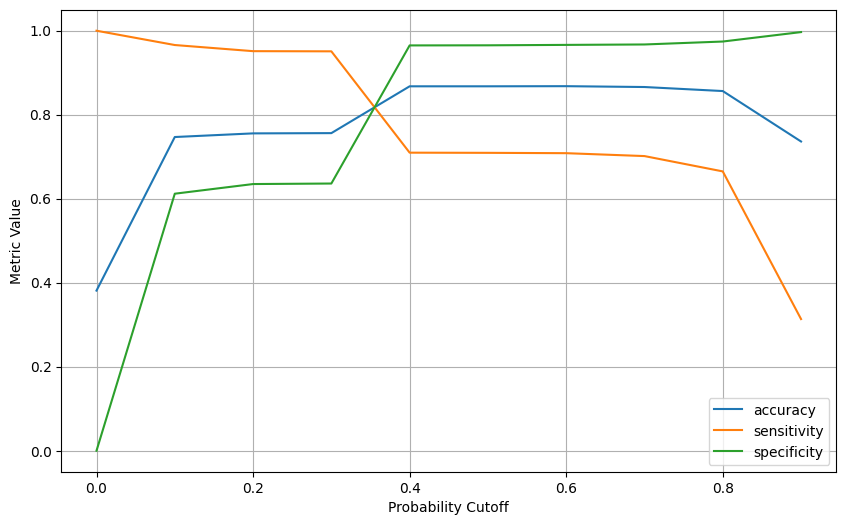

In [200]:
# ----------------------------------------
# Step 13 : Cutoff Curve Visualization
# ----------------------------------------

import matplotlib.pyplot as plt

# Plot all three metrics

cutoff_df[['accuracy',
           'sensitivity',
           'specificity']].plot(
    figsize=(10,6)
)

# Label x-axis

plt.xlabel('Probability Cutoff')

# Label y-axis

plt.ylabel('Metric Value')

# Show grid

plt.grid(True)

# Display graph

plt.show()

# `Step-14 Create Final Predictions on Training Data`

In [201]:
# -----------------------------------
# Step 14 : Final Predictions
# -----------------------------------

# Using chosen cutoff = 0.4

y_train_pred['final_predicted'] = y_train_pred.Conversion_Prob.map(
    lambda x: 1 if x > 0.4 else 0
)

In [202]:
y_train_pred.head()

,Converted,Conversion_Prob,0.0,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,final_predicted
0,0,0.004356,1,0,0,0,0,0,0,0,0,0,0
1,0,0.334171,1,1,1,1,0,0,0,0,0,0,0
2,0,0.004356,1,0,0,0,0,0,0,0,0,0,0
3,0,0.057385,1,0,0,0,0,0,0,0,0,0,0
4,0,0.334171,1,1,1,1,0,0,0,0,0,0,0


In [203]:
# Import confusion matrix

from sklearn.metrics import confusion_matrix

# Create confusion matrix

confusion = confusion_matrix(
    y_train_pred.Converted,
    y_train_pred.final_predicted
)

print(confusion)

'''
Suppose:

[[TN FP]
 [FN TP]]

Where:

TN = True Negatives
FP = False Positives
FN = False Negatives
TP = True Positives
'''

[[3862  140]
 [ 716 1750]]


'\nSuppose:\n\n[[TN FP]\n [FN TP]]\n\nWhere:\n\nTN = True Negatives\nFP = False Positives\nFN = False Negatives\nTP = True Positives\n'

In [204]:
# Accuracy

from sklearn.metrics import accuracy_score

accuracy_score(
    y_train_pred.Converted,
    y_train_pred.final_predicted
)

0.8676561533704391

In [205]:
# Precision

from sklearn.metrics import precision_score

precision_score(
    y_train_pred.Converted,
    y_train_pred.final_predicted
)

0.9259259259259259

In [206]:
# Recall Score

from sklearn.metrics import recall_score

recall_score(
    y_train_pred.Converted,
    y_train_pred.final_predicted
)

0.7096512570965126

In [207]:
# F1 Score

from sklearn.metrics import f1_score

f1_score(
    y_train_pred.Converted,
    y_train_pred.final_predicted
)

0.8034894398530762

# `Step-15 Test Set Validation`

In [208]:
# -------------------------------------
# Step 15 : Prepare Test Dataset
# -------------------------------------

# Select same columns used in training

X_test_final = X_test[X_train_rfe.columns]

In [209]:
# Add intercept term

X_test_sm = sm.add_constant(X_test_final)

In [210]:
model_columns = X_train_sm.columns.drop('const')
X_test_filtered_features = X_test_final[model_columns]
X_test_sm_corrected = sm.add_constant(X_test_filtered_features, has_constant='add')

y_test_pred = res.predict(X_test_sm_corrected.astype(float))

In [211]:
# Convert predictions into dataframe

y_test_pred = pd.DataFrame(
    y_test_pred
)

# Reset indices

y_test.reset_index(
    drop=True,
    inplace=True
)

y_test_pred.reset_index(
    drop=True,
    inplace=True
)

# Combine actual and predicted

y_pred_final = pd.concat(
    [y_test, y_test_pred],
    axis=1
)

# Rename columns

y_pred_final.columns = [
    'Converted',
    'Conversion_Prob'
]

# View output

y_pred_final.head()

,Converted,Conversion_Prob
0,1,0.874747
1,1,0.985565
2,1,0.894207
3,0,0.002652
4,1,0.830700


In [212]:
# Final prediction using chosen cutoff

y_pred_final['final_predicted'] = (
    y_pred_final.Conversion_Prob
    .map(lambda x: 1 if x > 0.4 else 0)
)

In [213]:
# Confusion matrix

from sklearn.metrics import confusion_matrix

confusion_test = confusion_matrix(
    y_pred_final.Converted,
    y_pred_final.final_predicted
)

print(confusion_test)

[[1610   67]
 [ 320  775]]


In [214]:
# Accuracy

from sklearn.metrics import accuracy_score

accuracy_score(
    y_pred_final.Converted,
    y_pred_final.final_predicted
)

0.8603896103896104

In [215]:
# Precision

from sklearn.metrics import precision_score

precision_score(
    y_pred_final.Converted,
    y_pred_final.final_predicted
)

0.9204275534441805

In [216]:
# Recall Score

from sklearn.metrics import recall_score

recall_score(
    y_pred_final.Converted,
    y_pred_final.final_predicted
)

0.7077625570776256

In [217]:
# F1 score

from sklearn.metrics import f1_score

f1_score(
    y_pred_final.Converted,
    y_pred_final.final_predicted
)

0.8002065049044915

# `Step-16 Create Lead Score (0-100)`

In [218]:
# --------------------------------------------------
# Step 16 : Create Lead Score
# --------------------------------------------------

# Convert probability into score out of 100

y_pred_final['Lead_Score'] = (
    y_pred_final['Conversion_Prob'] * 100
).round(2)

# View results

y_pred_final.head()

,Converted,Conversion_Prob,final_predicted,Lead_Score
0,1,0.874747,1,87.47
1,1,0.985565,1,98.56
2,1,0.894207,1,89.42
3,0,0.002652,0,0.27
4,1,0.830700,1,83.07


In [219]:
# Create final scored dataset

Lead_Scored_Data = pd.concat(
    [X_test.reset_index(drop=True),
     y_pred_final['Lead_Score']],
    axis=1
)

Lead_Scored_Data.head()

,TotalVisits,Total Time Spent on Website,Page Views Per Visit,Lead Origin_Landing Page Submission,Lead Origin_Lead Add Form,Lead Origin_Lead Import,Lead Origin_Quick Add Form,Lead Source_Direct Traffic,Lead Source_Facebook,Lead Source_Google,...,Last Notable Activity_Had a Phone Conversation,Last Notable Activity_Modified,Last Notable Activity_Olark Chat Conversation,Last Notable Activity_Page Visited on Website,Last Notable Activity_Resubscribed to emails,Last Notable Activity_SMS Sent,Last Notable Activity_Unreachable,Last Notable Activity_Unsubscribed,Last Notable Activity_View in browser link Clicked,Lead_Score
0,8.0,1011,6.0,False,False,False,False,True,False,False,...,False,False,False,False,False,True,False,False,False,87.47
1,0.0,0,0.0,False,True,False,False,False,False,False,...,False,False,False,False,False,True,False,False,False,98.56
2,5.0,59,5.0,False,False,False,False,False,False,True,...,False,False,False,False,False,False,True,False,False,89.42
3,0.0,0,0.0,False,False,False,False,False,False,False,...,False,True,False,False,False,False,False,False,False,0.27
4,0.0,0,0.0,False,True,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,83.07


# `Step-17 Identify Most Important Variable`

In [220]:
print(res.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:              Converted   No. Observations:                 6468
Model:                            GLM   Df Residuals:                     6454
Model Family:                Binomial   Df Model:                           13
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -2089.0
Date:                Mon, 22 Jun 2026   Deviance:                       4178.1
Time:                        19:51:05   Pearson chi2:                 1.15e+04
No. Iterations:                     8   Pseudo R-squ. (CS):             0.4951
Covariance Type:            nonrobust                                         
                                                           coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------

In [221]:
# --------------------------------------------------
# Step 17 : Important Features
# --------------------------------------------------

important_features = pd.DataFrame()

important_features['Feature'] = res.params.index
important_features['Coefficient'] = res.params.values

important_features = important_features.sort_values(
    by='Coefficient',
    ascending=False
)

important_features

,Feature,Coefficient
5,Tags_Closed by Horizzon,8.974638
6,Tags_Lost to EINS,8.515397
12,Last Notable Activity_Had a Phone Conversation,3.769856
8,Tags_Will revert after reading the email,3.669761
4,Tags_Busy,2.877489
3,What is your current occupation_Working Profes...,2.823828
13,Last Notable Activity_SMS Sent,2.632975
1,Lead Origin_Lead Add Form,2.279975
7,Tags_Ringing,-1.072704
9,Tags_switched off,-1.436225


In [222]:
# Top Positive Drivers

important_features.head(10)

,Feature,Coefficient
5,Tags_Closed by Horizzon,8.974638
6,Tags_Lost to EINS,8.515397
12,Last Notable Activity_Had a Phone Conversation,3.769856
8,Tags_Will revert after reading the email,3.669761
4,Tags_Busy,2.877489
3,What is your current occupation_Working Profes...,2.823828
13,Last Notable Activity_SMS Sent,2.632975
1,Lead Origin_Lead Add Form,2.279975
7,Tags_Ringing,-1.072704
9,Tags_switched off,-1.436225


In [223]:
# Top Negative Drivers

important_features.tail(10)

,Feature,Coefficient
4,Tags_Busy,2.877489
3,What is your current occupation_Working Profes...,2.823828
13,Last Notable Activity_SMS Sent,2.632975
1,Lead Origin_Lead Add Form,2.279975
7,Tags_Ringing,-1.072704
9,Tags_switched off,-1.436225
2,Last Activity_Olark Chat Conversation,-1.570612
10,Lead Profile_Potential Lead,-1.915508
0,const,-2.443632
11,Lead Profile_Student of SomeSchool,-3.234882


# `Lead Scoring Case Study - Executive Summary`

## Objective

The objective of this project was to build a Lead Scoring Model that assigns a score to each lead and predicts the likelihood of conversion. The model helps the sales team focus on high-potential leads and improve conversion efficiency.

## Methodology

A Logistic Regression model was developed using demographic information, lead source details, website engagement metrics, and sales interaction variables. Recursive Feature Elimination (RFE) and statistical significance testing were used to select the final predictors.

The dataset was split into training and testing sets, followed by feature scaling and model evaluation.

## Model Performance

### Training Set Performance

* Accuracy: 86.77%
* Precision: 92.59%
* Recall: 70.97%
* F1 Score: 80.35%

### Test Set Performance

* Accuracy: 86.04%
* Precision: 92.04%
* Recall: 70.78%
* F1 Score: 80.02%

The similarity between training and testing performance indicates that the model generalizes well and does not suffer from significant overfitting.

## Key Drivers of Conversion

Positive factors influencing conversion include:

* Tags_Closed by Horizzon
* Tags_Lost to EINS
* Last Notable Activity_Had a Phone Conversation
* Tags_Will revert after reading the email
* Working Professional occupation
* SMS communication
* Lead Add Form origin

Negative factors influencing conversion include:

* Student of SomeSchool profile
* Potential Lead profile
* Switched Off tag
* Olark Chat Conversation activity

## Business Recommendations

1. Prioritize leads with Lead Scores greater than 40.
2. Focus sales efforts on working professionals and highly engaged prospects.
3. Increase follow-up activities through phone calls and SMS communication.
4. Allocate marketing budgets toward lead sources generating higher conversion rates.
5. Use the Lead Score as an automated qualification mechanism to improve sales productivity.

## Conclusion

The Logistic Regression model successfully predicts lead conversion with high precision and good overall accuracy. The generated Lead Score can be used to identify and prioritize high-quality leads, enabling the sales team to improve conversion rates and optimize resource allocation.
